# Buổi B5: Đường cong và quá khớp, khi uốn quá tay máy học vẹt

**Hiện trường.** Ông Ba trồng cà phê. Ông thử bón **nhiều mức phân khác nhau** trên 40 thửa ruộng và ghi **năng suất** mỗi thửa. Ông có kinh nghiệm: *bón thêm thì lên năng suất, nhưng bón quá tay thì cây xót, năng suất tụt xuống.* Ông nhờ ta vẽ đường dự đoán, và hỏi một câu rất thực tế: *"Bón bao nhiêu thì tối ưu?"*

Đường thẳng (B1) chỉ biết "cứ tăng" hoặc "cứ giảm", không biết "tăng rồi giảm". Ta cần **đường cong**.

**Câu hỏi của buổi này:** *làm sao uốn cong đường hồi quy, và uốn đến đâu thì đủ, đến đâu thì quá tay?*

**Mindset của người làm dữ liệu:** mô hình càng **linh hoạt** càng dễ bám sát dữ liệu cũ, kể cả bám vào **nhiễu**. Mục tiêu không phải là khớp dữ liệu cũ nhất, mà là *đoán đúng dữ liệu mới*.

**Lưu ý đặc biệt:** ở buổi này ta **tự sinh dữ liệu** bằng một công thức đã biết (thêm nhiễu ngẫu nhiên), để *biết trước sự thật* và đo được việc mô hình lệch sự thật bao nhiêu. Dữ liệu thật không cho ta điều đó. Cuối buổi ta quay lại dữ liệu bệnh nhân thật. Buổi này dùng lại cú pháp từ A1 đến B4 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Đường thẳng thất bại ở đâu: nhìn phần dư |
| Chặng 2 | Uốn cong bằng cách thêm cột tự chế: PolynomialFeatures |
| Chặng 3 | Uốn quá tay: tăng bậc đa thức và đo trên dữ liệu mới |
| Chặng 4 | Vì sao quá khớp xảy ra, và thuốc chữa: thêm dữ liệu |
| Chặng 5 | Dữ liệu thật: bệnh nhân có cần đường cong không? |
| Chặng 6 | Chọn bậc cho đúng, bằng tập kiểm định |

## Chặng 1: Đường thẳng thất bại ở đâu, nhìn phần dư

**Câu hỏi:** dữ liệu của ông Ba trông thế nào, và đường thẳng sai ở chỗ nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
def true_yield(x):
    return 20 + 9 * x - 0.4 * x ** 2

def farm_data(n, seed):
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 20, n)
    return pd.DataFrame({"fertilizer": x}), pd.Series(true_yield(x) + rng.normal(0, 6, n), name="yield")

X, y = farm_data(40, seed=3)
print(X.assign(yield_per_ha=y.round(1)).head(4).round(1))

   fertilizer  yield_per_ha
0         1.7          24.2
1         4.7          55.3
2        16.0          65.7
3        11.6          67.9


**Giải thích từng dòng**

- `def true_yield(x):`: (đã học `def`) **sự thật ẩn** mà ta tự đặt ra: năng suất = 20 + 9x − 0,4x². Đây là hàm **bậc hai** (hình parabol úp): tăng rồi giảm. Ngoài đời không ai biết công thức này, ở đây ta cố tình biết để chấm điểm.
- `def farm_data(n, seed):`: hàm tạo `n` thửa ruộng: mỗi thửa có lượng phân và năng suất.
- `rng = np.random.default_rng(seed)`: (đã học) bộ phát số ngẫu nhiên, hạt giống truyền vào.
- `x = rng.uniform(0, 20, n)`: **mới:** `rng.uniform(thấp, cao, n)` sinh `n` số **đều đặn trong khoảng** từ 0 đến 20 (kg phân trên một đơn vị diện tích, đơn vị quy ước).
- `pd.Series(true_yield(x) + rng.normal(0, 6, n), name="yield")`: (đã học `rng.normal`) năng suất = **sự thật + nhiễu**. Nhiễu `normal(0, 6, n)` có trung bình 0, phân tán 6: đại diện cho thời tiết, đất, sâu bệnh... những thứ mà phân bón không giải thích được.
- `X, y = farm_data(40, seed=3)`: 40 thửa ruộng của ông Ba.
- `X.assign(yield_per_ha=y.round(1))`: **mới:** `.assign(tên_mới=cột)` thêm một cột vào bảng (trả về **bản mới**, không sửa bảng cũ), để xem cả đề lẫn đáp án cạnh nhau. Ta đặt tên `yield_per_ha` vì `yield` là từ khóa của Python, không dùng làm tên trong `assign` được.

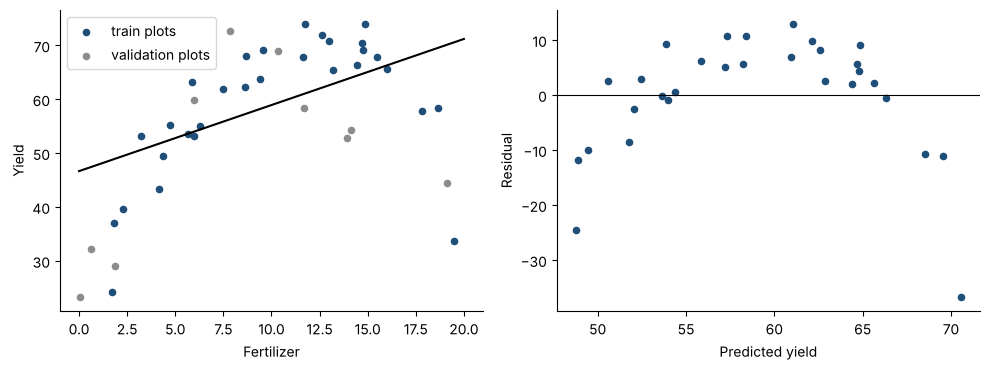

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=0)
line = LinearRegression().fit(X_train, y_train)
grid = pd.DataFrame({"fertilizer": np.linspace(0, 20, 100)})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(X_train["fertilizer"], y_train, color=BLUE, s=20, label="train plots")
axes[0].scatter(X_val["fertilizer"], y_val, color=GRAY, s=20, label="validation plots")
axes[0].plot(grid["fertilizer"], line.predict(grid), color="black")
axes[0].set_xlabel("Fertilizer"); axes[0].set_ylabel("Yield"); axes[0].legend()
axes[1].scatter(line.predict(X_train), y_train - line.predict(X_train), color=BLUE, s=20)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Predicted yield"); axes[1].set_ylabel("Residual")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `from sklearn... import ... (ba dòng)`: (đã học) máy hồi quy, chia sổ, MAE.
- `X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=0)`: (đã học) chia 30 thửa để học, 10 thửa để thi. Tên `X_val` (validation, tập **kiểm định**) thay cho `X_test` vì ta sẽ dùng nó để *chọn mô hình*, như tập validation ở A4. Tập thi thật sự sẽ sinh sau.
- `line = LinearRegression().fit(X_train, y_train)`: (đã học) đường thẳng.
- `grid = pd.DataFrame({"fertilizer": np.linspace(0, 20, 100)})`: 100 mức phân đều nhau từ 0 đến 20 để vẽ đường mượt.
- `axes[0] ... axes[1] ...`: (đã học) hai ô: ô trái là chấm và đường thẳng, ô phải là **biểu đồ phần dư** (như B2): dự đoán trên ngang, phần dư trên dọc.

**Cách đọc**

- **Con số:** hình trái: đường thẳng **dốc nhẹ lên** (từ khoảng 47 lên 71), trong khi các chấm lại tạo hình **vòm**: thấp ở hai đầu, cao ở giữa, và tụt xuống ở bên phải (phân nhiều).
- **Bức tranh (ô phải):** phần dư **không phải đám mây quanh 0**, mà là một **hình cong**: các chấm xếp thành chữ U úp. Ở B2 ta đã nói: *nếu phần dư xếp thành đường cong rõ ràng thì đường thẳng không đủ.* Đây chính là dấu hiệu đó. Đường thẳng đoán thấp ở giữa (bón vừa) và đoán cao ở hai đầu.
- **Hệ quả:** đường thẳng sẽ khuyên ông Ba "cứ bón nhiều thêm thì năng suất cứ tăng", trong khi các thửa bón nhiều nhất lại **tụt**. Sự thật là có một mức bón **tối ưu ở giữa**.

**Mang về chặng 1:** phần dư xếp thành hình cong là **tín hiệu** đường thẳng không đủ. Nhìn biểu đồ phần dư trước khi quyết định đổi mô hình.

## Chặng 2: Uốn cong bằng cách thêm cột tự chế, PolynomialFeatures

**Câu hỏi:** làm sao để *cùng một máy hồi quy tuyến tính* vẽ được đường cong?

Mẹo hay nhất của hồi quy: **đường cong chỉ là đường thẳng trên cột mới**. Nếu ta thêm một cột **x²** (lượng phân bình phương), thì mô hình y = a + b₁·x + b₂·x² vẫn **tuyến tính theo các hệ số** (b₁, b₂), nên `LinearRegression` giải được y nguyên. Nhưng *đồ thị theo x* thì cong.

In [4]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
poly = PolynomialFeatures(degree=3, include_bias=False)
poly.fit(X_train)
new_cols = pd.DataFrame(poly.transform(X_train), columns=poly.get_feature_names_out()).round(1)
new_cols.head(4)

,fertilizer,fertilizer^2,fertilizer^3
0,15.5,239.2,3699.1
1,12.6,158.8,2001.2
2,14.8,220.1,3264.9
3,16.0,256.8,4115.6


**Giải thích từng dòng**

- `from sklearn.preprocessing import PolynomialFeatures, StandardScaler`: (đã học module `preprocessing` ở B4) `PolynomialFeatures` là một **bộ biến đổi** (có `fit` và `transform`) tạo ra các cột lũy thừa.
- `poly = PolynomialFeatures(degree=3, include_bias=False)`: `degree=3` là **bậc**: tạo x, x², x³. `include_bias=False` bảo đừng tạo cột toàn số 1 (vì `LinearRegression` đã có `intercept_` lo việc đó).
- `poly.fit(X_train)`: `fit` ở đây đơn giản: chỉ ghi nhớ **có bao nhiêu cột đầu vào** để biết phải sinh bao nhiêu cột đầu ra. Không học số liệu nào.
- `pd.DataFrame(poly.transform(X_train), columns=poly.get_feature_names_out())`: `transform` sinh bảng cột mới; `get_feature_names_out()` đặt tên cột (`fertilizer`, `fertilizer^2`, `fertilizer^3`).

**Cách đọc:** từ **một cột** `fertilizer`, ta có **ba cột**: x, x², x³. Hàng đầu, nếu x = 11,5 thì x² = 132,3 và x³ = 1521. Máy hồi quy tuyến tính coi ba cột này như **ba chỉ số khác nhau** của thửa ruộng (như `bmi`, `bp`, `s5` ở B3). Cái đường cong chỉ là hệ quả: *không có phép màu mới*, chỉ có cột mới.

Bậc 1 là đường thẳng, bậc 2 là parabol (một khúc cong), bậc 3 uốn được hai khúc... Ta dựng pipeline (B4): sinh cột bậc cao, **chuẩn hóa** (vì x³ lớn hơn x rất nhiều lần), rồi hồi quy. Thử bậc 2:

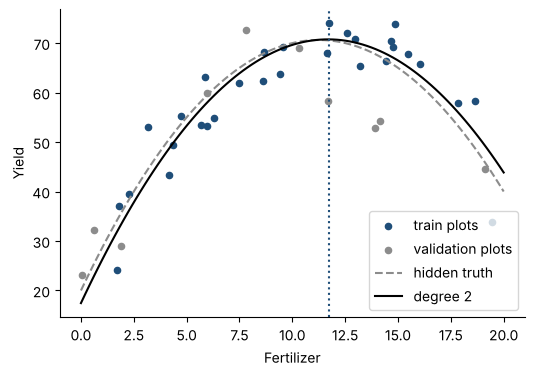

Best fertilizer by the model: 11.7 | by the hidden truth: 11.2


In [5]:
def poly_model(degree):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())

curve = poly_model(2).fit(X_train, y_train)
plt.scatter(X_train["fertilizer"], y_train, color=BLUE, s=20, label="train plots")
plt.scatter(X_val["fertilizer"], y_val, color=GRAY, s=20, label="validation plots")
plt.plot(grid["fertilizer"], true_yield(grid["fertilizer"]), color=GRAY, linestyle="--", label="hidden truth")
plt.plot(grid["fertilizer"], curve.predict(grid), color="black", label="degree 2")
best_x = grid["fertilizer"][np.argmax(curve.predict(grid))]
plt.axvline(best_x, color=BLUE, linestyle=":")
plt.xlabel("Fertilizer"); plt.ylabel("Yield"); plt.legend(); plt.show()
print("Best fertilizer by the model:", round(best_x, 1), "| by the hidden truth: 11.2")

**Giải thích từng dòng**

- `def poly_model(degree):`: hàm tạo pipeline cho bất kỳ bậc nào: gọn để thử nhiều bậc.
- `plt.plot(grid["fertilizer"], true_yield(grid["fertilizer"]), ...)`: vẽ **sự thật ẩn** bằng nét đứt xám. Đây là thứ chỉ có trong bài sinh dữ liệu.
- `best_x = grid["fertilizer"][np.argmax(curve.predict(grid))]`: `np.argmax` là **vị trí của số lớn nhất** (ngược với `argmin` ở B1). Lấy mức phân tương ứng: đỉnh của đường cong dự đoán.
- `plt.axvline(best_x, ...)`: (đã học) vạch dọc đánh dấu đỉnh.

**Cách đọc**

- **Con số:** đường bậc 2 có đỉnh ở mức phân khoảng **11,7**, gần mức tối ưu thật **11,2** (nơi 20 + 9x − 0,4x² cao nhất).
- **Bức tranh:** đường đen **gần như chồng lên đường nét đứt xám** (sự thật ẩn), dù máy chỉ thấy 30 thửa ruộng có nhiễu. Đường cong bắt được ý "tăng rồi giảm" mà đường thẳng không bắt được.
- **Câu trả lời cho ông Ba:** *bón khoảng 11 đến 12 đơn vị là tối ưu.* Quan trọng: đây là một **quyết định** rút ra được từ mô hình mà đường thẳng không thể cho.

**Mang về chặng 2:** `PolynomialFeatures(degree=d)` tạo cột x, x², ..., xᵈ; sau đó vẫn dùng `LinearRegression`. Đường cong là *tuyến tính trên cột mới*. Bậc là **số khúc cong** mô hình được phép có.

## Chặng 3: Uốn quá tay, tăng bậc đa thức và đo trên dữ liệu mới

**Câu hỏi:** nếu bậc 2 tốt hơn bậc 1, bậc 8 hay bậc 12 có tốt hơn nữa không?

Để chấm công bằng, ta tận dụng điều chỉ có ở dữ liệu tự sinh: tạo thêm **2000 thửa ruộng hoàn toàn mới** từ cùng cơ chế, làm **tập thi thật**. Rồi thử các bậc từ 1 đến 12.

In [6]:
X_new, y_new = farm_data(2000, seed=99)
rows = []
for degree in range(1, 13):
    m = poly_model(degree).fit(X_train, y_train)
    rows.append({
        "degree": degree,
        "train MAE": mean_absolute_error(y_train, m.predict(X_train)),
        "validation MAE (10 plots)": mean_absolute_error(y_val, m.predict(X_val)),
        "fresh MAE (2000 plots)": mean_absolute_error(y_new, m.predict(X_new)),
        "biggest |coef|": np.abs(m[-1].coef_).max(),
    })
sweep = pd.DataFrame(rows).round(2)
sweep[sweep["degree"].isin([1, 2, 3, 5, 8, 12])]

,degree,train MAE,validation MAE (10 plots),fresh MAE (2000 plots),biggest |coef|
0,1,7.83,13.93,10.98,6.43
1,2,3.95,7.68,4.98,47.74
2,3,3.51,7.43,5.12,29.29
4,5,3.39,8.45,5.50,143.94
7,8,2.78,38.44,11.37,293825.24
11,12,2.69,26.79,9.39,36432.03


**Giải thích từng dòng**

- `X_new, y_new = farm_data(2000, seed=99)`: 2000 thửa **chưa từng thấy**, hạt giống khác. Đây là cách đo "sai bao nhiêu trên dữ liệu mới thật sự".
- `for degree in range(1, 13):`: (đã học) thử bậc 1 đến 12.
- `m = poly_model(degree).fit(X_train, y_train)`: học bậc đó, chỉ trên 30 thửa.
- `np.abs(m[-1].coef_).max()`: (đã học `pipe[-1]` ở B4) hệ số **lớn nhất về độ lớn** trong mô hình: để theo dõi chuyện hệ số "phình" thế nào.
- `sweep[sweep["degree"].isin([1, 2, 3, 5, 8, 12])]`: (đã học `isin`) chỉ hiện sáu bậc để bảng gọn.

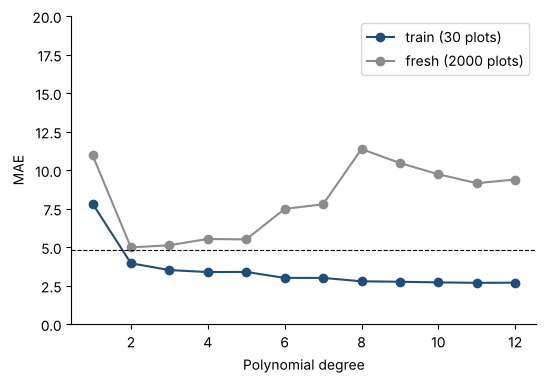

In [7]:
plt.plot(sweep["degree"], sweep["train MAE"], "o-", color=BLUE, label="train (30 plots)")
plt.plot(sweep["degree"], sweep["fresh MAE (2000 plots)"], "o-", color=GRAY, label="fresh (2000 plots)")
plt.axhline(6 * np.sqrt(2 / np.pi), color="black", linestyle="--", linewidth=0.8)
plt.ylim(0, 20)
plt.xlabel("Polynomial degree"); plt.ylabel("MAE"); plt.legend(); plt.show()

**Giải thích từng dòng**

- `plt.axhline(6 * np.sqrt(2 / np.pi), ...)`: vạch ngang ở mức **sai số không thể tránh**. Vì nhiễu có độ phân tán 6, ngay cả *người biết trước công thức thật* cũng sai trung bình khoảng 4,8 (công thức `6 × √(2/π)` là MAE kỳ vọng của nhiễu hình chuông). Không mô hình nào qua được vạch này.
- `plt.ylim(0, 20)`: (đã học) cắt trục dọc ở 20 để không bị bậc quá cao phá hỏng thang đo.

**Cách đọc**

- **Con số:** sai số trên 30 thửa **học** giảm đều: từ **7,8** (bậc 1) xuống **3,9** (bậc 2), rồi xuống **2,7** (bậc 12). Sai số trên **2000 thửa mới** thì: **11,0** (bậc 1), **5,0** (bậc 2, sát vạch không thể tránh 4,8), rồi **tăng lại**: **5,5** (bậc 5), **11,4** (bậc 8), **9,4** (bậc 12). Hệ số lớn nhất ở bậc 8 lên cỡ **hàng trăm nghìn**.
- **Bức tranh:** hai đường **tách nhau** như cái kéo: đường xanh (học) cứ đi xuống mãi; đường xám (dữ liệu mới) đi xuống rồi **bật lên**, tạo hình chữ **U**. Đáy chữ U là bậc 2 đến 3, đúng bậc của sự thật. **Bậc càng cao thì khớp tập học càng tốt, nhưng đoán dữ liệu mới càng tệ.**
- **Tên gọi:** mô hình bậc quá thấp (bậc 1) bị **dưới khớp** (underfit): quá đơn giản để bắt được hình dạng thật. Mô hình bậc quá cao (bậc 8, 12) bị **quá khớp** (overfit): nó bám vào cả **nhiễu** của 30 thửa, như học thuộc lòng đáp án thay vì hiểu quy luật.

Nhìn bằng hình sẽ rõ hơn con số:

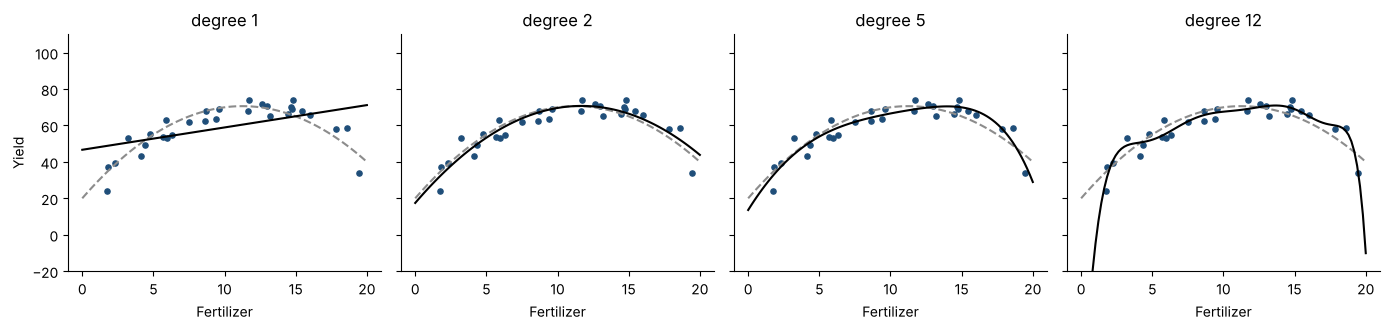

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, degree in zip(axes, [1, 2, 5, 12]):
    m = poly_model(degree).fit(X_train, y_train)
    ax.scatter(X_train["fertilizer"], y_train, color=BLUE, s=14)
    ax.plot(grid["fertilizer"], true_yield(grid["fertilizer"]), color=GRAY, linestyle="--")
    ax.plot(grid["fertilizer"], m.predict(grid), color="black")
    ax.set_ylim(-20, 110); ax.set_title(f"degree {degree}"); ax.set_xlabel("Fertilizer")
axes[0].set_ylabel("Yield")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)`: (đã học) bốn ô cạnh nhau, chung trục dọc.
- `for ax, degree in zip(axes, [1, 2, 5, 12]):`: (đã học `zip`) ghép từng ô với từng bậc, vẽ lần lượt.
- `ax.set_ylim(-20, 110)`: (đã học) cố định trục dọc để các ô so với nhau được.

**Cách đọc**

- **Con số:** bậc 1 sai khoảng 11 trên dữ liệu mới; bậc 2 khoảng 5; bậc 12 khoảng 9 (nhưng với dải phân tán rất lớn ở rìa).
- **Bức tranh:**
  - **Bậc 1:** đường thẳng cứng nhắc, bỏ lỡ vòm.
  - **Bậc 2:** ôm sát đường nét đứt (sự thật). Đẹp.
  - **Bậc 5:** bắt đầu uốn thêm những khúc **không có thật**, đặc biệt ở hai đầu.
  - **Bậc 12:** ở giữa, đường uốn lượn **nhẹ** để chạm sát từng chấm xanh (nhìn qua khá đẹp), nhưng ở **hai đầu mút** thì **lao thẳng xuống** (bên trái xuống dưới −20, bên phải cũng chúi xuống). Nó đang "ghi nhớ" từng điểm, kể cả điểm do nhiễu, và phải trả giá ở rìa.
- **Điểm nguy hiểm nhất:** ở rìa (phân rất ít hoặc rất nhiều), đường cong bậc cao **dự đoán những năng suất phi lý** (năng suất âm). Lưu ý đường bậc 12 *trông* khá ổn ở giữa: nếu chỉ nhìn phần giữa, ta dễ tin nó. Một lời khuyên dựa trên đường đó có thể làm ông Ba mất mùa.

**Mang về chặng 3:** tăng bậc làm sai số **trên tập học luôn giảm** nhưng sai số **trên dữ liệu mới giảm rồi tăng** (hình chữ U). Quá thấp là *dưới khớp*, quá cao là *quá khớp*. Có một **sàn sai số không thể tránh** do nhiễu: đừng đòi mô hình vượt qua nó.

## Chặng 4: Vì sao quá khớp xảy ra, và thuốc chữa, thêm dữ liệu

**Câu hỏi:** quá khớp có phải do bậc cao tự nó xấu không?

Không hẳn. Bậc 12 có **13 tham số** (12 hệ số và một `intercept_`) mà chỉ có **30 thửa ruộng** để học: số "núm vặn" gần bằng số dữ liệu, nên máy vặn các núm cho vừa vặn từng điểm. **Quá khớp là chuyện tỉ lệ giữa độ phức tạp của mô hình và lượng dữ liệu.** Thử cùng bậc 2 và bậc 12 nhưng với lượng dữ liệu học tăng dần:

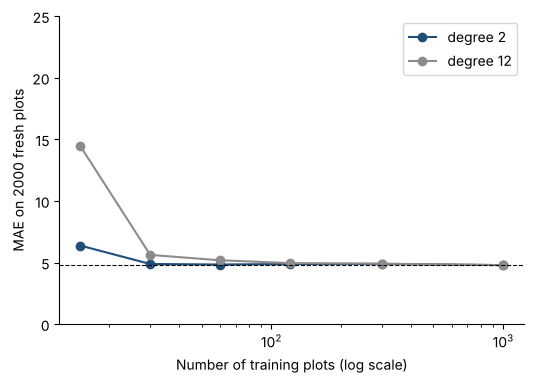

degree,2,12
n,,
15,6.4,14.4
30,4.9,5.6
60,4.8,5.2
120,4.9,5.0
300,4.9,4.9
1000,4.8,4.8


In [9]:
sizes = [15, 30, 60, 120, 300, 1000]
learn = []
for n in sizes:
    Xn, yn = farm_data(n, seed=7)
    for degree in [2, 12]:
        m = poly_model(degree).fit(Xn, yn)
        learn.append({"n": n, "degree": degree, "fresh MAE": mean_absolute_error(y_new, m.predict(X_new))})
learn = pd.DataFrame(learn)
for degree, color in [(2, BLUE), (12, GRAY)]:
    part = learn[learn["degree"] == degree]
    plt.plot(part["n"], part["fresh MAE"], "o-", color=color, label=f"degree {degree}")
plt.xscale("log"); plt.ylim(0, 25)
plt.axhline(6 * np.sqrt(2 / np.pi), color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Number of training plots (log scale)"); plt.ylabel("MAE on 2000 fresh plots")
plt.legend(); plt.show()
learn.pivot(index="n", columns="degree", values="fresh MAE").round(1)

**Giải thích từng dòng**

- `sizes = [15, 30, 60, 120, 300, 1000]`: các cỡ tập học thử, tăng dần.
- `Xn, yn = farm_data(n, seed=7)`: sinh dữ liệu học cỡ `n`. Dùng tên `Xn`, `yn` để khỏi đè lên `X_new` đang dùng làm tập thi.
- `for degree in [2, 12]:`: (đã học vòng lặp lồng nhau) với mỗi cỡ, thử cả bậc 2 và bậc 12.
- `plt.xscale("log")`: **mới:** trục ngang theo **thang logarit** (mỗi vạch cách nhau một *hệ số nhân*, thay vì cộng), vì cỡ tập đi từ 15 đến 1000, chênh nhau cả chục lần.
- `learn.pivot(index="n", columns="degree", values="fresh MAE")`: **mới:** `.pivot(...)` **xoay bảng dài thành bảng rộng**: mỗi dòng một cỡ `n`, mỗi cột một bậc, ô là sai số. Dễ so hai bậc cạnh nhau.

**Cách đọc**

- **Con số:** với **15** thửa, bậc 12 sai **14,4**, gấp hơn hai lần bậc 2 (6,4); với **30** và **60** thửa, bậc 12 vẫn tệ hơn bậc 2 một chút (5,6 so với 4,9; và 5,2 so với 4,8); từ **120** thửa trở đi hai bậc **gần như ngang nhau** (cả hai quanh sàn ~4,8).
- **Bức tranh:** đường xám (bậc 12) bắt đầu rất cao rồi **rớt dần** khi có thêm dữ liệu, đuổi kịp đường xanh (bậc 2) ở bên phải. Một điều thành thật: ở cỡ 30 thửa, bậc 12 ở đây chỉ sai 5,6, trong khi ở chặng 3 (cũng 30 thửa nhưng **một mẫu khác**) nó sai 9,4. *Mức độ quá khớp phụ thuộc cả vào việc ta may rủi gặp mẫu nào*: càng ít dữ liệu, kết quả càng dao động. Có đủ dữ liệu, mô hình linh hoạt **không còn học vẹt** vì không đủ chỗ cho nhiễu "ở ẩn". Còn bậc 2 tốt ngay từ cỡ nhỏ vì nó **đúng dạng** của sự thật.
- **Thuốc chữa quá khớp**, theo thứ tự nên thử:
  1. **Thêm dữ liệu** (tốt nhất, nhưng thường tốn kém).
  2. **Giảm độ phức tạp** của mô hình (bậc thấp hơn, ít cột hơn).
  3. **Phạt hệ số lớn** (Ridge và Lasso, buổi B6).
- **Ý nghĩa thực tế:** khi chỉ có **ít dữ liệu** (rất hay gặp ngoài đời), hãy chọn mô hình **đơn giản**. Khi dữ liệu dồi dào, mô hình phức tạp mới có đất sống.

**Mang về chặng 4:** quá khớp là chuyện **độ phức tạp so với lượng dữ liệu**. Ít dữ liệu thì mô hình đơn giản thắng; nhiều dữ liệu thì mô hình phức tạp mới phát huy. Chữa quá khớp: thêm dữ liệu, giảm phức tạp, hoặc phạt hệ số (B6).

## Chặng 5: Dữ liệu thật, bệnh nhân có cần đường cong không?

**Câu hỏi:** ở dữ liệu thật ta không biết sự thật. Làm sao biết có cần uốn cong không?

Quay lại bảng bệnh nhân. Ta thử bậc 1 đến 6 trên cột `bmi`, mỗi bậc **lặp 30 lần chia** để lấy trung bình (bài học A4).

In [10]:
from sklearn.datasets import load_diabetes
patients = load_diabetes(as_frame=True, scaled=False).frame
Xp, yp = patients[["bmi"]], patients["target"]
rows = []
for degree in range(1, 7):
    train_r2, test_r2 = [], []
    for seed in range(30):
        a, b, c, d = train_test_split(Xp, yp, test_size=0.2, random_state=seed)
        m = poly_model(degree).fit(a, c)
        train_r2.append(m.score(a, c)); test_r2.append(m.score(b, d))
    rows.append({"degree": degree, "train R2": np.mean(train_r2), "test R2": np.mean(test_r2)})
pd.DataFrame(rows).round(3)

,degree,train R2,test R2
0,1,0.348,0.312
1,2,0.348,0.310
2,3,0.350,0.305
3,4,0.351,0.294
4,5,0.354,0.300
5,6,0.358,0.051


**Giải thích từng dòng**

- `patients = load_diabetes(...); Xp, yp = ...`: (đã học) bảng bệnh nhân, đề là **một cột** `bmi`.
- `for degree in range(1, 7): for seed in range(30): ...`: (đã học) vòng lặp lồng nhau: sáu bậc × 30 lần chia.
- `m = poly_model(degree).fit(a, c)`: dùng lại hàm `poly_model` của chặng 2.

**Cách đọc**

- **Con số:** R² thi trung bình qua 30 lần chia: bậc 1 là **0,312**, bậc 2 là **0,310**, bậc 3 là **0,305**, bậc 4 là **0,294**, bậc 5 là **0,300**, và bậc 6 **sụp xuống 0,051**. R² train chỉ nhích từ 0,348 lên 0,358.
- **Bức tranh:** khác hẳn chặng 3. Ở dữ liệu bệnh nhân, **uốn cong gần như không đem lại gì**: điểm thi **không tăng chút nào** (giảm nhẹ rồi sụp ở bậc 6). Điều đó nói rằng quan hệ BMI với điểm bệnh **khá thẳng**; sự phân tán là do *nhiễu và các yếu tố khác*, không phải do hình cong. Nếu ai bảo "cho thêm đường cong thì R² sẽ tăng vọt" thì ta có số liệu để trả lời: *không, ở đây thì không*.
- **Bài học nghề:** đường cong là công cụ chữa bệnh **"phần dư xếp thành hình cong"** (chặng 1). Đừng uống thuốc khi không có bệnh.

In [11]:
all_X = patients.drop(columns="target")
rows = []
for degree in [1, 2]:
    train_r2, test_r2 = [], []
    for seed in range(30):
        a, b, c, d = train_test_split(all_X, yp, test_size=0.2, random_state=seed)
        m = poly_model(degree).fit(a, c)
        train_r2.append(m.score(a, c)); test_r2.append(m.score(b, d))
    rows.append({"degree": degree, "columns after expansion": m[0].n_output_features_, "train R2": np.mean(train_r2), "test R2": np.mean(test_r2)})
pd.DataFrame(rows).round(3)

,degree,columns after expansion,train R2,test R2
0,1,10,0.526,0.458
1,2,65,0.615,0.317


**Giải thích từng dòng**

- `all_X = patients.drop(columns="target")`: (đã học) cả mười cột đề.
- `for degree in [1, 2]:`: so sánh bậc 1 (thường) với bậc 2 (thêm bình phương và các tích đôi).
- `m[0].n_output_features_`: `m[0]` là bước đầu của pipeline (`PolynomialFeatures`); `n_output_features_` là **số cột nó đã sinh ra**.

**Cách đọc**

- **Con số:** bậc 1 dùng 10 cột, R² train **0,526**, R² thi **0,458**. Bậc 2 **sinh ra 65 cột** (10 cột gốc, 10 cột bình phương, 45 cột tích từng đôi), R² train **vọt lên 0,615** nhưng R² thi **tụt xuống 0,317**.
- **Bức tranh:** đây là quá khớp của chặng 3, nhưng ở dạng **nhiều cột thay vì nhiều bậc**: 353 bệnh nhân học và 65 cột để vặn, máy bắt đầu ghi nhớ nhiễu. Cũng cùng hình chiếc kéo: train lên, thi xuống.
- **Câu hỏi mở cho buổi sau:** có cách nào *giữ nhiều cột nhưng ép máy không vặn quá tay* không? Có, đó là **Ridge và Lasso** (B6).

**Mang về chặng 5:** đường cong chỉ giúp khi dữ liệu thật sự cong (phần dư hình cong). Trên dữ liệu bệnh nhân, bậc 1 gần như đủ, và thêm cột bậc cao (65 cột) làm điểm thi **tụt**. Luôn đo trên tập thi, và lặp nhiều lần chia.

## Chặng 6: Chọn bậc cho đúng, bằng tập kiểm định

**Câu hỏi:** ngoài đời ta không có 2000 thửa ruộng "mới". Làm sao chọn bậc?

Ở A4 ta học **ba tập**: học, kiểm định (validation), thi. Quy trình đúng:

1. **Học** nhiều mô hình (nhiều bậc) trên **tập học**.
2. **Chọn** mô hình tốt nhất theo điểm trên **tập kiểm định**.
3. **Chỉ một lần** chấm mô hình đã chọn trên **tập thi**, để báo cáo.

Tập kiểm định đóng vai "2000 thửa mới" của ta, nhưng nhỏ hơn nhiều nên **nhiễu hơn**. Hãy xem nó chọn bậc nào, bằng bảng ở chặng 3:

In [12]:
chosen = sweep.loc[sweep["validation MAE (10 plots)"].idxmin(), ["degree", "validation MAE (10 plots)", "fresh MAE (2000 plots)"]]
print("Degree picked by the 10 validation plots:", int(chosen["degree"]))
print("Its error on validation:", round(chosen["validation MAE (10 plots)"], 1), "| on 2000 fresh plots:", round(chosen["fresh MAE (2000 plots)"], 1))
print("Best possible degree by the fresh plots:", int(sweep.loc[sweep["fresh MAE (2000 plots)"].idxmin(), "degree"]))

Degree picked by the 10 validation plots: 3
Its error on validation: 7.4 | on 2000 fresh plots: 5.1
Best possible degree by the fresh plots: 2


**Giải thích từng dòng**

- `sweep["validation MAE (10 plots)"].idxmin()`: **mới:** `.idxmin()` cho **nhãn dòng** của giá trị nhỏ nhất (`argmin` cho vị trí, còn `idxmin` cho nhãn). Ở đây là dòng của bậc có sai số kiểm định nhỏ nhất.
- `sweep.loc[nhãn, [các cột]]`: (đã học `.loc`) lấy ba cột của dòng được chọn.
- `sweep.loc[sweep["fresh MAE (2000 plots)"].idxmin(), "degree"]`: bậc tốt nhất nếu ta có thể nhìn trộm 2000 thửa mới (chỉ có trong bài sinh dữ liệu).

**Cách đọc**

- **Con số:** 10 thửa kiểm định chọn **bậc 3** (sai số khoảng 7,4); trong khi nhìn trộm 2000 thửa mới thì bậc tốt nhất là **bậc 2** (5,0). Bậc 3 trên dữ liệu mới sai khoảng 5,1: gần ngang bậc 2.
- **Bức tranh:** tập kiểm định chọn **gần đúng** nhưng không chính xác: 10 thửa quá ít, nên chênh lệch giữa bậc 2 và bậc 3 (7,7 so với 7,4) nằm trong vùng nhiễu. Quan trọng là nó **không chọn bậc 8 hay 12**, những bậc có sai số kiểm định 27 đến 38. Công cụ kiểm định có tác dụng chính là *loại bỏ các lựa chọn tồi*, ít khi phân biệt nổi hai lựa chọn tốt gần nhau.
- **Quy tắc thực hành:** nếu hai mô hình ngang ngửa, chọn mô hình **đơn giản hơn** (bậc thấp hơn). Nó ít rủi ro quá khớp, dễ giải thích hơn.
- **Cách làm đáng tin hơn** (sẽ học ở phần D): **kiểm định chéo**, tức là lặp việc chia và chấm nhiều lần thay vì dựa vào 10 thửa duy nhất, giống cách ta lặp 30 lần chia ở chặng 5.

## Phán quyết và bài học nghề

**Phán quyết cho ông Ba.** Dùng **đường cong bậc 2**: mức phân tối ưu khoảng **11 đơn vị** (sự thật là 11,2). Đường thẳng không trả lời được câu hỏi này; đường bậc 12 trông "khớp" nhất trên 30 thửa nhưng **phá hỏng** dự đoán ở hai đầu mút. Với 30 thửa, mô hình đơn giản là lựa chọn an toàn.

**Bài học nghề.**

1. **Phần dư xếp thành hình cong** là tín hiệu cần đường cong. Nếu không thấy thì không cần.
2. **Đường cong = đường thẳng trên cột mới** (`PolynomialFeatures`); luôn **chuẩn hóa** sau đó.
3. **Bậc càng cao, sai số tập học càng thấp, nhưng sai số dữ liệu mới có hình chữ U.** Dưới khớp bên trái đáy, quá khớp bên phải.
4. **Quá khớp là chuyện độ phức tạp so với lượng dữ liệu**: ít dữ liệu thì chọn đơn giản.
5. **Có sàn sai số không thể tránh** do nhiễu: đừng đuổi theo những cải thiện dưới sàn.
6. **Chọn mô hình bằng tập kiểm định**, báo cáo bằng tập thi; hai mô hình ngang nhau thì chọn mô hình đơn giản.

**Một điều thành thật:** trong bài này ta *biết trước sự thật*, nên thấy rõ ràng mọi thứ. Ngoài đời, "sự thật" không có, tập kiểm định thì nhỏ và nhiễu, nên việc chọn bậc **luôn kèm một mức không chắc chắn**. Hãy nhớ rằng đường cong hợp lý không đồng nghĩa là đường cong đúng.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Phần dư xếp thành hình cong là tín hiệu đường thẳng không đủ. |
| 2 | `PolynomialFeatures(degree=d)` sinh cột x, x², ..., xᵈ; đường cong là tuyến tính trên cột mới; nhớ chuẩn hóa. |
| 3 | Tăng bậc: sai số tập học luôn giảm, sai số dữ liệu mới có hình chữ U. Dưới khớp và quá khớp. |
| 4 | Quá khớp là chuyện độ phức tạp so với lượng dữ liệu; thuốc chữa: thêm dữ liệu, giảm phức tạp, phạt hệ số. |
| 5 | Chỉ uốn cong khi dữ liệu thật sự cong; thêm cột bậc cao có thể làm điểm thi tụt. |
| 6 | Chọn bậc bằng tập kiểm định; hai mô hình ngang nhau thì chọn đơn giản hơn. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Thêm cột x², x³ | đặc trưng đa thức | `PolynomialFeatures(degree=3)` |
| Số khúc cong mô hình được phép có | bậc đa thức | `degree=` |
| Quá đơn giản, bỏ lỡ quy luật | dưới khớp (underfit) | bậc quá thấp |
| Học vẹt, bám vào nhiễu | quá khớp (overfit) | bậc quá cao |
| Sai số không thể tránh do nhiễu | sàn sai số (noise floor) | (không mô hình nào vượt) |
| Tập để chọn mô hình | tập kiểm định (validation) | `X_val, y_val` |
| Xoay bảng dài thành bảng rộng | pivot | `df.pivot(...)` |
| Nhãn dòng của giá trị nhỏ nhất | idxmin | `s.idxmin()` |

**Thử thách tự làm**

1. Ở chặng 1, đổi hệ số nhiễu `rng.normal(0, 6, n)` thành 12 (nhiễu gấp đôi). Bậc nào tốt nhất trên 2000 thửa mới? Sàn sai số thay đổi thế nào, và chữ U có đổi hình không?
2. Dùng `farm_data(40, seed=3)` nhưng **đổi `random_state`** khi chia tập học và kiểm định (thử 0 đến 4). Bậc nào được tập kiểm định chọn mỗi lần? Có nhất quán không?
3. Kể chuyện với dữ liệu khác: dùng `load_diabetes`, đề là cột `s5`, và đo bậc 1 đến 6 qua 30 lần chia như chặng 5. Có cần đường cong không? Vẽ biểu đồ phần dư để kiểm tra.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Nhận ra khi nào đường thẳng không đủ bằng biểu đồ phần dư.
- [ ] Dựng mô hình đa thức bằng PolynomialFeatures và pipeline.
- [ ] Giải thích dưới khớp và quá khớp bằng hình chữ U.
- [ ] Biết quá khớp liên quan thế nào đến lượng dữ liệu.
- [ ] Biết dữ liệu thật không phải lúc nào cũng cần đường cong.
- [ ] Chọn mức phức tạp bằng tập kiểm định và áp dụng nguyên tắc "ngang nhau thì chọn đơn giản".

## Phần thưởng (Tip pro): Đa thức bậc cao và rủi ro ở hai đầu mút


Ở chặng 3 ta thấy đường bậc 12 "bay vọt" ở hai đầu. Hiện tượng này (gọi là **hiệu ứng Runge**) có hệ quả thực tế: **đừng bao giờ dự đoán ngoài vùng dữ liệu bằng đa thức bậc cao**. Chạy ô dưới để thấy: cùng mô hình bậc 2 và bậc 12, hỏi xem phân bón bằng **25** (ngoài khoảng 0 đến 20 đã thấy) thì dự đoán năng suất là bao nhiêu, so với sự thật.

In [13]:
beyond = pd.DataFrame({"fertilizer": [25.0]})
print("Truth at 25:", round(true_yield(25.0), 1))
for degree in [1, 2, 12]:
    print(f"degree {degree:2d} predicts:", round(poly_model(degree).fit(X_train, y_train).predict(beyond)[0], 1))

Truth at 25: -5.0
degree  1 predicts: 77.3
degree  2 predicts: 1.7
degree 12 predicts: -16065.7


**Giải thích từng dòng**

- `beyond = pd.DataFrame({"fertilizer": [25.0]})`: một thửa với mức phân **ngoài** vùng dữ liệu (0 đến 20): đây là **ngoại suy** (A4).
- `print(f"degree {degree:2d} predicts:", ...)`: (đã học `f-string`) in dự đoán của từng bậc cạnh sự thật.

**Cách đọc:** sự thật tại 25 là **−5** (bón quá nhiều thì mất mùa, cây chết). Đường thẳng (bậc 1) dự đoán **77** ("càng bón càng tốt", sai hoàn toàn về hướng); bậc 2 dự đoán **1,7** (đúng hướng, lệch khoảng 7); còn bậc 12 dự đoán **−16 066**, một số **vô nghĩa**. Ngoại suy bằng đa thức bậc cao rất nguy hiểm; ngoại suy bằng đường thẳng thì sai kiểu khác.